# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Ananda Avenzia
- **Email:** avensiaananda@gmail.com
- **ID Dicoding:**  DS009B6X0173

## Menentukan Pertanyaan Bisnis

**Konteks bisnis.** Dataset ini berisi catatan penyewaan sepeda *Capital Bikeshare* di Washington D.C. selama dua tahun (2011–2012), lengkap dengan informasi cuaca dan kalender. Anggaplah kita adalah tim analitik operator sistem bike sharing yang perlu memutuskan **kapan dan di mana armada harus disiapkan, kapan perawatan dijadwalkan, dan kapan promosi paling efektif**.

Pertanyaan bisnis disusun dengan kerangka **SMART**:

| # | Pertanyaan | S | M | A | R | T |
|---|---|---|---|---|---|---|
| 1 | Pada jam berapa puncak penyewaan sepeda terjadi di **hari kerja** dibandingkan **akhir pekan/hari libur**, dan berapa rata-rata penyewaan per jam pada jam puncak tersebut selama 2011–2012? | Jam puncak per tipe hari | Rata-rata penyewaan per jam | Menentukan penempatan sepeda & jadwal perawatan | Efisiensi operasional armada | 2011–2012 |
| 2 | Berapa selisih rata-rata penyewaan **harian** antar **musim** dan antar **kondisi cuaca**, dan berapa persen penurunan pada cuaca hujan/salju ringan dibandingkan cuaca cerah selama 2011–2012? | Musim & cuaca | Rata-rata harian & % selisih | Menyesuaikan kapasitas, promosi & perawatan musiman | Permintaan sangat dipengaruhi lingkungan | 2011–2012 |
| 3 | Berapa pertumbuhan total penyewaan bulanan tahun **2012 dibandingkan 2011** (Year-over-Year), pada bulan apa pertumbuhan tertinggi dan terendah, dan apakah pengguna **casual** atau **registered** yang tumbuh lebih cepat? | Pertumbuhan YoY per bulan & tipe pengguna | % pertumbuhan | Menentukan fokus promosi & konversi ke membership | Pertumbuhan adalah tujuan utama bisnis | Jan 2011 – Des 2012 |

- **Pertanyaan 1:** Pada jam berapa puncak penyewaan sepeda terjadi di hari kerja dibandingkan akhir pekan/hari libur, dan berapa rata-rata penyewaan per jam pada jam puncak tersebut selama 2011–2012?
- **Pertanyaan 2:** Berapa selisih rata-rata penyewaan harian antar musim dan antar kondisi cuaca, dan berapa persen penurunan pada cuaca hujan/salju ringan dibandingkan cuaca cerah selama 2011–2012?
- **Pertanyaan 3:** Berapa pertumbuhan total penyewaan bulanan tahun 2012 dibandingkan 2011 (YoY), pada bulan apa pertumbuhan tertinggi dan terendah, dan apakah pengguna casual atau registered yang tumbuh lebih cepat?

## Import Semua Packages/Library yang Digunakan

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Pengaturan tampilan
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid', font_scale=1.0)

# Palet warna konsisten untuk seluruh visualisasi
C_PRIMARY = '#2A6F97'   # warna utama
C_ACCENT = '#E07A5F'    # warna sorotan
C_MUTED = '#B8C0C8'     # warna pendukung

## Data Wrangling

### Gathering Data

Dataset terdiri dari dua berkas: `day.csv` (agregasi harian, 731 hari) dan `hour.csv` (agregasi per jam, 17.379 jam). Keduanya dimuat sebagai DataFrame. Jika notebook dijalankan di Google Colab, unggah folder `data/` terlebih dahulu (atau ubah `DATA_DIR`).

#### Load day_df dan hour_df

In [2]:
DATA_DIR = 'data'

day_df = pd.read_csv(os.path.join(DATA_DIR, 'day.csv'))
hour_df = pd.read_csv(os.path.join(DATA_DIR, 'hour.csv'))

print('day_df  :', day_df.shape)
print('hour_df :', hour_df.shape)
day_df.head()

day_df  : (731, 16)
hour_df : (17379, 17)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [3]:
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- `day_df` berisi 731 baris (1 Jan 2011 – 31 Des 2012) dengan 16 kolom, sedangkan `hour_df` berisi 17.379 baris dengan tambahan kolom `hr` (jam 0–23).
- Kolom `temp`, `atemp`, `hum`, dan `windspeed` tampak berskala 0–1 (ternormalisasi), dan kolom kategori (`season`, `yr`, `mnth`, `weathersit`, `weekday`) masih berupa kode angka. Hal ini akan diperiksa pada tahap *assessing*.

### Assessing Data

#### Identifying missing value & duplicate data

In [4]:
for nama, df in [('day_df', day_df), ('hour_df', hour_df)]:
    print(f'=== {nama} ===')
    print('Jumlah baris      :', df.shape[0])
    print('Total missing     :', df.isna().sum().sum())
    print('Jumlah duplikat   :', df.duplicated().sum())
    print()

day_df.info()

=== day_df ===
Jumlah baris      : 731
Total missing     : 0
Jumlah duplikat   : 0

=== hour_df ===
Jumlah baris      : 17379
Total missing     : 0
Jumlah duplikat   : 0

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64

#### Identifying invalid value (tipe data & kode kategori)

In [5]:
print('Tipe data dteday :', day_df['dteday'].dtype, '(seharusnya datetime)\n')

for kolom in ['season', 'yr', 'mnth', 'weekday', 'weathersit']:
    print(f'{kolom:11s}:', sorted(day_df[kolom].unique().tolist()))

print('\nSebaran weathersit pada hour_df:')
print(hour_df['weathersit'].value_counts().sort_index())

print('\nRentang nilai kolom ternormalisasi (day_df):')
day_df[['temp', 'atemp', 'hum', 'windspeed']].describe().loc[['min', 'max']]

Tipe data dteday : str (seharusnya datetime)

season     : [1, 2, 3, 4]
yr         : [0, 1]
mnth       : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
weekday    : [0, 1, 2, 3, 4, 5, 6]
weathersit : [1, 2, 3]

Sebaran weathersit pada hour_df:
weathersit
1    11413
2     4544
3     1419
4        3
Name: count, dtype: int64

Rentang nilai kolom ternormalisasi (day_df):


,temp,atemp,hum,windspeed
min,0.059130,0.079070,0.0000,0.022392
max,0.861667,0.840896,0.9725,0.507463


#### Identifying inaccurate value

In [6]:
print('--- Kelembapan (hum) bernilai 0 ---')
print(day_df.loc[day_df['hum'] == 0, ['dteday', 'hum']])
print('Jumlah baris hum = 0 di hour_df :', (hour_df['hum'] == 0).sum())
print('Tanggal terkait                 :', hour_df.loc[hour_df['hum'] == 0, 'dteday'].unique())

print('\n--- Kecepatan angin (windspeed) bernilai 0 ---')
print('day_df  :', (day_df['windspeed'] == 0).sum(), 'baris')
print('hour_df :', (hour_df['windspeed'] == 0).sum(), 'baris',
      f"({(hour_df['windspeed'] == 0).mean():.1%} dari seluruh jam)")

--- Kelembapan (hum) bernilai 0 ---
        dteday  hum
68  2011-03-10  0.0
Jumlah baris hum = 0 di hour_df : 22
Tanggal terkait                 : <ArrowStringArray>
['2011-03-10']
Length: 1, dtype: str

--- Kecepatan angin (windspeed) bernilai 0 ---
day_df  : 0 baris
hour_df : 2180 baris (12.5% dari seluruh jam)


#### Identifying inconsistent value (uji konsistensi antar kolom & antar tabel)

In [7]:
# 1) cnt harus = casual + registered
print('cnt != casual + registered (day) :', (day_df['cnt'] != day_df['casual'] + day_df['registered']).sum())
print('cnt != casual + registered (hour):', (hour_df['cnt'] != hour_df['casual'] + hour_df['registered']).sum())

# 2) workingday harus = bukan Sabtu/Minggu dan bukan libur (weekday: 0 = Minggu, 6 = Sabtu)
workingday_seharusnya = ((~day_df['weekday'].isin([0, 6])) & (day_df['holiday'] == 0)).astype(int)
print('workingday tidak konsisten       :', (workingday_seharusnya != day_df['workingday']).sum())

# 3) total penyewaan per hari pada hour_df harus sama dengan day_df
cek = hour_df.groupby('dteday')['cnt'].sum().reset_index().merge(day_df[['dteday', 'cnt']], on='dteday', suffixes=('_hour', '_day'))
print('Selisih total harian hour vs day :', (cek['cnt_hour'] != cek['cnt_day']).sum())

cnt != casual + registered (day) : 0
cnt != casual + registered (hour): 0
workingday tidak konsisten       : 0
Selisih total harian hour vs day : 0


#### Identifying outlier

In [8]:
def hitung_outlier(df, kolom):
    q1, q3 = df[kolom].quantile([0.25, 0.75])
    iqr = q3 - q1
    batas_bawah, batas_atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (df[kolom] < batas_bawah) | (df[kolom] > batas_atas)
    return pd.Series({'batas_bawah': batas_bawah, 'batas_atas': batas_atas, 'jumlah_outlier': mask.sum()})

pd.DataFrame({k: hitung_outlier(day_df, k) for k in ['casual', 'registered', 'cnt', 'hum', 'windspeed']}).T

,batas_bawah,batas_atas,jumlah_outlier
casual,-855.250000,2266.750000,44.0
registered,-922.250000,8195.750000,0.0
cnt,-1054.000000,10162.000000,0.0
hum,0.204687,1.045521,2.0
windspeed,-0.012447,0.380611,13.0


**Steps to Take:**
1. **Invalid value (tipe data):** ubah `dteday` dari *string* menjadi `datetime` pada kedua DataFrame.
2. **Inaccurate value:** kelembapan `hum = 0` hanya muncul pada 10 Maret 2011 (1 baris di `day_df`, 22 jam di `hour_df`) dan tidak masuk akal secara fisik → ubah menjadi `NaN`, lalu isi dengan **interpolasi linear** dari data sekitarnya. Nilai `windspeed = 0` pada `hour_df` (±12,5% jam) kemungkinan merupakan keterbatasan resolusi sensor; kolom ini **tidak dipakai** untuk analisis per jam dan hanya dipakai pada level harian (`day_df`, tanpa nilai 0).
3. **Inconsistent / tidak informatif:** kode angka pada `season`, `yr`, `mnth`, `weekday`, `weathersit` diganti **label** yang mudah dibaca, dan dibuat kolom `day_type` (Hari Kerja vs Akhir Pekan/Libur). Kolom `temp`, `atemp`, `hum`, `windspeed` dikembalikan ke satuan aslinya sesuai dokumentasi dataset (suhu × 41, suhu terasa × 50, kelembapan × 100, angin × 67).
4. **Outlier:** nilai ekstrem pada `casual` perlu ditelaah dulu apakah error atau permintaan yang valid sebelum diputuskan.
5. **Missing value & duplikat:** tidak ditemukan, tidak ada tindakan. Uji konsistensi antar kolom/tabel lolos semua.

**Insight:**
- Kualitas data secara umum **baik**: tidak ada missing value maupun duplikat, `cnt = casual + registered` selalu terpenuhi, `workingday` konsisten dengan `weekday`/`holiday`, dan total per jam sama persis dengan total harian.
- Masalah yang ditemukan: tipe data tanggal tidak tepat, kode kategori tidak informatif, nilai skala ternormalisasi, kelembapan 0 pada satu hari, dan outlier pada `casual`/`windspeed`.
- Kategori cuaca 4 (hujan/salju lebat) hanya muncul **3 jam** di `hour_df` dan tidak ada di `day_df`, sehingga tidak dapat dianalisis secara andal.

### Cleaning Data

#### Fixing invalid value: tipe data tanggal

In [9]:
for df in (day_df, hour_df):
    df['dteday'] = pd.to_datetime(df['dteday'])

print(day_df['dteday'].dtype, '|', hour_df['dteday'].dtype)
print(day_df['dteday'].min().date(), 's.d.', day_df['dteday'].max().date())

datetime64[us] | datetime64[us]
2011-01-01 s.d. 2012-12-31


#### Fixing inaccurate value: kelembapan bernilai 0

In [10]:
for df in (day_df, hour_df):
    df['hum'] = df['hum'].replace(0, np.nan).interpolate(method='linear')

print('hum = 0 tersisa (day) :', (day_df['hum'] == 0).sum())
print('hum = 0 tersisa (hour):', (hour_df['hum'] == 0).sum())
print('Missing hum           :', day_df['hum'].isna().sum(), '|', hour_df['hum'].isna().sum())
print('\nNilai hum 10 Maret 2011 setelah interpolasi (day_df):')
day_df.loc[day_df['dteday'] == '2011-03-10', ['dteday', 'hum']]

hum = 0 tersisa (day) : 0
hum = 0 tersisa (hour): 0
Missing hum           : 0 | 0

Nilai hum 10 Maret 2011 setelah interpolasi (day_df):


,dteday,hum
68,2011-03-10,0.712491


#### Fixing inconsistent value: kode angka menjadi label & penyeragaman satuan

In [11]:
season_map = {1: 'Semi', 2: 'Panas', 3: 'Gugur', 4: 'Dingin'}
weather_map = {1: 'Cerah', 2: 'Berkabut/Berawan', 3: 'Hujan/Salju Ringan', 4: 'Hujan/Salju Lebat'}
weekday_map = {0: 'Minggu', 1: 'Senin', 2: 'Selasa', 3: 'Rabu', 4: 'Kamis', 5: 'Jumat', 6: 'Sabtu'}
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']
weekday_order = ['Senin', 'Selasa', 'Rabu', 'Kamis', 'Jumat', 'Sabtu', 'Minggu']

for df in (day_df, hour_df):
    df['season_label'] = pd.Categorical(df['season'].map(season_map), categories=list(season_map.values()), ordered=True)
    df['weather_label'] = pd.Categorical(df['weathersit'].map(weather_map), categories=list(weather_map.values()), ordered=True)
    df['weekday_name'] = pd.Categorical(df['weekday'].map(weekday_map), categories=weekday_order, ordered=True)
    df['year'] = df['yr'].map({0: 2011, 1: 2012})
    df['month_name'] = pd.Categorical(df['mnth'].map(lambda m: month_names[m - 1]), categories=month_names, ordered=True)
    df['day_type'] = pd.Categorical(np.where(df['workingday'] == 1, 'Hari Kerja', 'Akhir Pekan/Libur'),
                                    categories=['Hari Kerja', 'Akhir Pekan/Libur'], ordered=True)

    # Kembalikan ke satuan asli (sesuai dokumentasi dataset)
    df['temp_c'] = df['temp'] * 41
    df['atemp_c'] = df['atemp'] * 50
    df['hum_pct'] = df['hum'] * 100
    df['windspeed_kmh'] = df['windspeed'] * 67

kolom_lama = ['yr', 'temp', 'atemp', 'hum', 'windspeed']
day_df = day_df.drop(columns=kolom_lama).rename(columns={'mnth': 'month'})
hour_df = hour_df.drop(columns=kolom_lama).rename(columns={'mnth': 'month'})

day_df[['dteday', 'year', 'season_label', 'month_name', 'weekday_name', 'day_type', 'weather_label',
        'temp_c', 'hum_pct', 'windspeed_kmh', 'casual', 'registered', 'cnt']].head()

,dteday,year,season_label,month_name,weekday_name,day_type,weather_label,temp_c,hum_pct,windspeed_kmh,casual,registered,cnt
0,2011-01-01,2011,Semi,Jan,Sabtu,Akhir Pekan/Libur,Berkabut/Berawan,14.110847,80.5833,10.749882,331,654,985
1,2011-01-02,2011,Semi,Jan,Minggu,Akhir Pekan/Libur,Berkabut/Berawan,14.902598,69.6087,16.652113,131,670,801
2,2011-01-03,2011,Semi,Jan,Senin,Hari Kerja,Cerah,8.050924,43.7273,16.636703,120,1229,1349
3,2011-01-04,2011,Semi,Jan,Selasa,Hari Kerja,Cerah,8.200000,59.0435,10.739832,108,1454,1562
4,2011-01-05,2011,Semi,Jan,Rabu,Hari Kerja,Cerah,9.305237,43.6957,12.522300,82,1518,1600


#### Handling outlier: casual

In [12]:
# Telaah outlier 'casual' (metode IQR): apakah error atau permintaan yang valid?
q1, q3 = day_df['casual'].quantile([0.25, 0.75])
batas_atas = q3 + 1.5 * (q3 - q1)
outlier_casual = day_df[day_df['casual'] > batas_atas]

print('Jumlah outlier casual              :', len(outlier_casual))
print(f"Porsi terjadi di akhir pekan/libur : {(outlier_casual['day_type'] == 'Akhir Pekan/Libur').mean():.0%}")
print(f"Porsi terjadi di cuaca cerah       : {(outlier_casual['weather_label'] == 'Cerah').mean():.0%}")
print('Rata-rata suhu hari outlier (C)    :', round(outlier_casual['temp_c'].mean(), 1))
outlier_casual['day_type'].value_counts()

Jumlah outlier casual              : 44
Porsi terjadi di akhir pekan/libur : 98%
Porsi terjadi di cuaca cerah       : 73%
Rata-rata suhu hari outlier (C)    : 25.4


day_type
Akhir Pekan/Libur    43
Hari Kerja            1
Name: count, dtype: int64

**Keputusan:** outlier `casual` **tidak dihapus**. Sebagian besar terjadi pada akhir pekan/hari libur dengan cuaca cerah dan suhu hangat, yaitu kondisi yang memang mendorong penyewaan rekreasi. Jadi ini adalah lonjakan permintaan yang **valid** dan justru bagian dari pola yang ingin dipelajari. Outlier `windspeed` (13 hari) juga dipertahankan karena masih dalam rentang fisik yang wajar.

#### Simpan data bersih untuk dashboard

In [13]:
os.makedirs('dashboard', exist_ok=True)
hour_df.to_csv('dashboard/main_data.csv', index=False)
day_df.to_csv('dashboard/day_data.csv', index=False)

print('main_data.csv (per jam):', hour_df.shape)
print('day_data.csv  (harian) :', day_df.shape)
print('Total missing setelah cleaning:', day_df.isna().sum().sum(), '|', hour_df.isna().sum().sum())

main_data.csv (per jam): (17379, 22)
day_data.csv  (harian) : (731, 21)
Total missing setelah cleaning: 0 | 0


**Insight:**
- Seluruh masalah pada tahap *assessing* sudah ditangani: tipe tanggal benar, kelembapan 0 diperbaiki, kategori berlabel, dan satuan cuaca kembali ke satuan asli (°C, %, km/jam).
- Data bersih disimpan sebagai `dashboard/main_data.csv` (per jam) dan `dashboard/day_data.csv` (harian) agar dashboard Streamlit memakai data yang sama dengan notebook.

## Exploratory Data Analysis (EDA)

### Explore: gambaran umum data

In [14]:
day_df[['temp_c', 'hum_pct', 'windspeed_kmh', 'casual', 'registered', 'cnt']].describe().round(1)

,temp_c,hum_pct,windspeed_kmh,casual,registered,cnt
count,731.0,731.0,731.0,731.0,731.0,731.0
mean,20.3,62.9,12.8,848.2,3656.2,4504.3
std,7.5,14.1,5.2,686.6,1560.3,1937.2
min,2.4,18.8,1.5,2.0,20.0,22.0
25%,13.8,52.1,9.0,315.5,2497.0,3152.0
50%,20.4,62.7,12.1,713.0,3662.0,4548.0
75%,26.9,73.0,15.6,1096.0,4776.5,5956.0
max,35.3,97.2,34.0,3410.0,6946.0,8714.0


### Explore: pola penyewaan per jam menurut tipe hari (Pertanyaan 1)

In [15]:
# Rata-rata penyewaan per jam untuk setiap tipe hari
hourly_pattern = hour_df.groupby(['day_type', 'hr'], observed=True)['cnt'].mean().unstack(0).round(1)

for tipe in hourly_pattern.columns:
    s = hourly_pattern[tipe]
    print(f'== {tipe} ==')
    for jam, nilai in s.nlargest(3).items():
        print(f'   jam {jam:02d}:00  -> {nilai:.1f} sepeda/jam')
    print(f'   jam sepi (terendah): {s.idxmin():02d}:00 -> {s.min():.1f}')

print()
hourly_pattern.loc[[0, 3, 7, 8, 12, 13, 17, 18, 22]]

== Hari Kerja ==
   jam 17:00  -> 525.3 sepeda/jam
   jam 18:00  -> 492.2 sepeda/jam
   jam 08:00  -> 477.0 sepeda/jam
   jam sepi (terendah): 03:00 -> 4.9
== Akhir Pekan/Libur ==
   jam 13:00  -> 372.7 sepeda/jam
   jam 12:00  -> 366.3 sepeda/jam
   jam 14:00  -> 364.6 sepeda/jam
   jam sepi (terendah): 04:00 -> 8.3



day_type,Hari Kerja,Akhir Pekan/Libur
hr,,
0,36.8,90.8
3,4.9,25.8
7,290.6,43.4
8,477.0,105.7
12,200.8,366.3
13,198.4,372.7
17,525.3,323.5
18,492.2,281.1
22,138.4,116.1


In [16]:
# Perbandingan jam puncak antar tipe hari
kerja, libur = hourly_pattern['Hari Kerja'], hourly_pattern['Akhir Pekan/Libur']
print(f'Puncak sore hari kerja (17:00) vs puncak akhir pekan (13:00): {kerja[17]:.0f} vs {libur[13]:.0f}  -> {kerja[17] / libur[13] - 1:+.0%}')
print(f'Jam 08:00 hari kerja vs akhir pekan                       : {kerja[8]:.0f} vs {libur[8]:.0f}  -> {kerja[8] / libur[8]:.1f}x')
print(f'Rata-rata jam 00-05 hari kerja : {kerja.loc[0:5].mean():.1f} sepeda/jam')

# Komposisi pengguna per tipe hari
hour_df.groupby('day_type', observed=True)[['casual', 'registered']].mean().round(1)

Puncak sore hari kerja (17:00) vs puncak akhir pekan (13:00): 525 vs 373  -> +41%
Jam 08:00 hari kerja vs akhir pekan                       : 477 vs 106  -> 4.5x
Rata-rata jam 00-05 hari kerja : 16.2 sepeda/jam


,casual,registered
day_type,,
Hari Kerja,25.6,167.6
Akhir Pekan/Libur,57.4,124.0


**Insight:**
- **Hari kerja** memiliki **dua puncak komuter**: pagi pukul **08:00 (±477 sepeda/jam)** dan sore pukul **17:00 (±525 sepeda/jam)**, dengan 18:00 (±492) hampir setara.
- **Akhir pekan/libur** hanya memiliki **satu puncak landai** sekitar **13:00 (±373 sepeda/jam)** dengan plateau pukul 11:00–16:00.
- Puncak sore hari kerja ±41% lebih tinggi dari puncak akhir pekan, dan pukul 08:00 hari kerja ±4,5× lebih ramai dibanding akhir pekan.
- Dini hari (00:00–05:00) hari kerja sangat sepi (rata-rata < 20 sepeda/jam).

### Explore: musim & cuaca (Pertanyaan 2)

In [17]:
ringkasan_musim = day_df.groupby('season_label', observed=True)['cnt'].agg(['count', 'mean', 'median', 'max']).round(0)
ringkasan_musim['selisih_vs_gugur_%'] = ((ringkasan_musim['mean'] / ringkasan_musim.loc['Gugur', 'mean'] - 1) * 100).round(1)
ringkasan_musim

,count,mean,median,max,selisih_vs_gugur_%
season_label,,,,,
Semi,181,2604.0,2209.0,7836,-53.9
Panas,184,4992.0,4942.0,8362,-11.6
Gugur,188,5644.0,5354.0,8714,0.0
Dingin,178,4728.0,4634.0,8555,-16.2


In [18]:
ringkasan_cuaca = day_df.groupby('weather_label', observed=True)['cnt'].agg(['count', 'mean', 'median']).round(0)
ringkasan_cuaca['selisih_vs_cerah_%'] = ((ringkasan_cuaca['mean'] / ringkasan_cuaca.loc['Cerah', 'mean'] - 1) * 100).round(1)
ringkasan_cuaca

,count,mean,median,selisih_vs_cerah_%
weather_label,,,,
Cerah,463,4877.0,4844.0,0.0
Berkabut/Berawan,247,4036.0,4040.0,-17.2
Hujan/Salju Ringan,21,1803.0,1817.0,-63.0


In [19]:
# Interaksi musim x cuaca & korelasi dengan variabel cuaca numerik
print('Rata-rata penyewaan harian: musim x cuaca')
display_tbl = day_df.pivot_table(index='season_label', columns='weather_label', values='cnt', aggfunc='mean', observed=True).round(0)
print(display_tbl.to_string())

print('\nKorelasi dengan cnt:')
day_df[['cnt', 'temp_c', 'hum_pct', 'windspeed_kmh']].corr()['cnt'].drop('cnt').round(2)

Rata-rata penyewaan harian: musim x cuaca
weather_label   Cerah  Berkabut/Berawan  Hujan/Salju Ringan
season_label                                               
Semi           2811.0            2357.0               935.0
Panas          5549.0            4237.0              1169.0
Gugur          5878.0            5222.0              2752.0
Dingin         5044.0            4654.0              1962.0

Korelasi dengan cnt:


temp_c           0.63
hum_pct         -0.12
windspeed_kmh   -0.23
Name: cnt, dtype: float64

**Insight:**
- Musim **Gugur** paling ramai (±5.644 sepeda/hari), diikuti Panas (±4.992) dan Dingin (±4.728). Musim **Semi** terendah (±2.604), sekitar **54% lebih rendah** dari Gugur. Perlu dicatat bahwa pada dataset ini musim Semi mencakup bulan-bulan awal tahun (Jan–Mar) yang secara musiman dingin dan saat sistem baru berkembang.
- Cuaca **berkabut/berawan** menurunkan penyewaan ±**17%** dan cuaca **hujan/salju ringan** menurunkannya hingga ±**63%** dibanding hari cerah (±4.877 → ±1.803 sepeda/hari). Namun hanya ada **21 hari** cuaca hujan/salju ringan, sehingga estimasinya lebih tidak pasti.
- Suhu berkorelasi positif sedang dengan penyewaan (**r ≈ 0,63**), kecepatan angin berkorelasi negatif lemah (r ≈ −0,23), dan kelembapan berkorelasi negatif sangat lemah (r ≈ −0,12).

### Explore: pertumbuhan 2012 vs 2011 (Pertanyaan 3)

In [20]:
pivot_bulanan = day_df.pivot_table(index='month', columns='year', values=['cnt', 'casual', 'registered'], aggfunc='sum')

yoy = pd.DataFrame({
    'cnt_2011': pivot_bulanan['cnt'][2011],
    'cnt_2012': pivot_bulanan['cnt'][2012],
    'yoy_total_%': (pivot_bulanan['cnt'][2012] / pivot_bulanan['cnt'][2011] - 1) * 100,
    'yoy_casual_%': (pivot_bulanan['casual'][2012] / pivot_bulanan['casual'][2011] - 1) * 100,
    'yoy_registered_%': (pivot_bulanan['registered'][2012] / pivot_bulanan['registered'][2011] - 1) * 100,
})
yoy.index = month_names
yoy.round(1)

,cnt_2011,cnt_2012,yoy_total_%,yoy_casual_%,yoy_registered_%
Jan,38189,96744,153.3,191.9,150.0
Feb,48215,103137,113.9,39.7,124.9
Mar,64045,164875,157.4,146.5,160.2
Apr,94870,174224,83.6,72.1,87.2
Mei,135821,195865,44.2,42.5,44.7
Jun,143512,202830,41.3,41.4,41.3
Jul,141341,203607,44.1,14.4,54.4
Agu,136691,214503,56.9,49.8,58.8
Sep,127418,218573,71.5,64.9,73.3
Okt,123511,198841,61.0,36.9,67.2


In [21]:
tahunan = day_df.groupby('year')[['casual', 'registered', 'cnt']].sum()
tahunan['porsi_casual_%'] = (tahunan['casual'] / tahunan['cnt'] * 100).round(1)
print(tahunan.to_string())

print('\nPertumbuhan tahunan 2012 vs 2011 (%):')
print((tahunan[['casual', 'registered', 'cnt']].pct_change().loc[2012] * 100).round(1).to_string())
print('\nBulan YoY tertinggi:', yoy['yoy_total_%'].idxmax(), round(yoy['yoy_total_%'].max(), 1), '%')
print('Bulan YoY terendah :', yoy['yoy_total_%'].idxmin(), round(yoy['yoy_total_%'].min(), 1), '%')

      casual  registered      cnt  porsi_casual_%
year                                             
2011  247252      995851  1243103            19.9
2012  372765     1676811  2049576            18.2

Pertumbuhan tahunan 2012 vs 2011 (%):
casual        50.8
registered    68.4
cnt           64.9

Bulan YoY tertinggi: Mar 157.4 %
Bulan YoY terendah : Jun 41.3 %


**Insight:**
- Total penyewaan tumbuh **+64,9%**: dari 1.243.103 (2011) menjadi 2.049.576 (2012).
- Pengguna **registered tumbuh lebih cepat (+68,4%)** dibanding **casual (+50,8%)**, sehingga porsi casual turun dari 19,9% menjadi 18,2%.
- Pertumbuhan tertinggi terjadi pada **Maret (+157%)** dan **Januari (+153%)**, tetapi ini sebagian besar **efek basis rendah** karena awal 2011 adalah masa awal sistem. Pertumbuhan paling "murni" terlihat di bulan-bulan pertengahan/akhir tahun, terendah pada **Juni (+41,3%)**.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Pada jam berapa puncak penyewaan terjadi di hari kerja dibandingkan akhir pekan/libur?

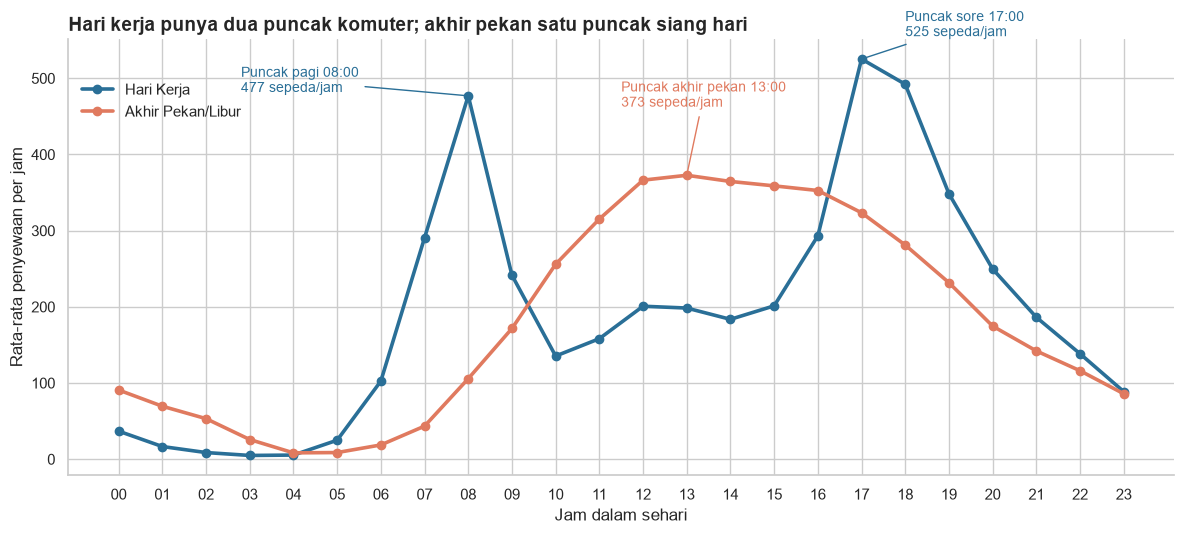

In [22]:
fig, ax = plt.subplots(figsize=(12, 5.5))

warna = {'Hari Kerja': C_PRIMARY, 'Akhir Pekan/Libur': C_ACCENT}
for tipe, c in warna.items():
    s = hourly_pattern[tipe]
    ax.plot(s.index, s.values, marker='o', lw=2.6, color=c, label=tipe)

# Anotasi jam puncak
kerja, libur = hourly_pattern['Hari Kerja'], hourly_pattern['Akhir Pekan/Libur']
pagi, sore, siang = kerja.loc[6:11].idxmax(), kerja.loc[15:20].idxmax(), libur.idxmax()
ax.annotate(f'Puncak pagi {pagi:02d}:00\n{kerja[pagi]:.0f} sepeda/jam', xy=(pagi, kerja[pagi]), xytext=(pagi - 5.2, kerja[pagi] + 5), color=C_PRIMARY, fontsize=10, arrowprops=dict(arrowstyle='-', color=C_PRIMARY))
ax.annotate(f'Puncak sore {sore:02d}:00\n{kerja[sore]:.0f} sepeda/jam', xy=(sore, kerja[sore]), xytext=(sore + 1.0, kerja[sore] + 30), color=C_PRIMARY, fontsize=10, arrowprops=dict(arrowstyle='-', color=C_PRIMARY))
ax.annotate(f'Puncak akhir pekan {siang:02d}:00\n{libur[siang]:.0f} sepeda/jam', xy=(siang, libur[siang]), xytext=(siang - 1.5, libur[siang] + 90), color=C_ACCENT, fontsize=10, arrowprops=dict(arrowstyle='-', color=C_ACCENT))

ax.set_xticks(range(0, 24))
ax.set_xticklabels([f'{h:02d}' for h in range(0, 24)])
ax.set_xlabel('Jam dalam sehari')
ax.set_ylabel('Rata-rata penyewaan per jam')
ax.set_title('Hari kerja punya dua puncak komuter; akhir pekan satu puncak siang hari', loc='left', fontsize=14, fontweight='bold')
ax.legend(frameon=False, loc='upper left', bbox_to_anchor=(0.0, 0.93))
sns.despine()
plt.tight_layout()
plt.show()

**Penjelasan:** Garis biru (hari kerja) membentuk pola "M" dengan puncak pukul 08:00 dan 17:00, yang mencerminkan perjalanan berangkat dan pulang kerja. Garis oranye (akhir pekan/libur) membentuk satu gundukan landai dengan puncak sekitar 13:00, yang mencerminkan penggunaan rekreasi. Pada dini hari hari kerja, permintaan hampir nol.

### Pertanyaan 2: Seberapa besar pengaruh musim dan cuaca terhadap penyewaan harian?

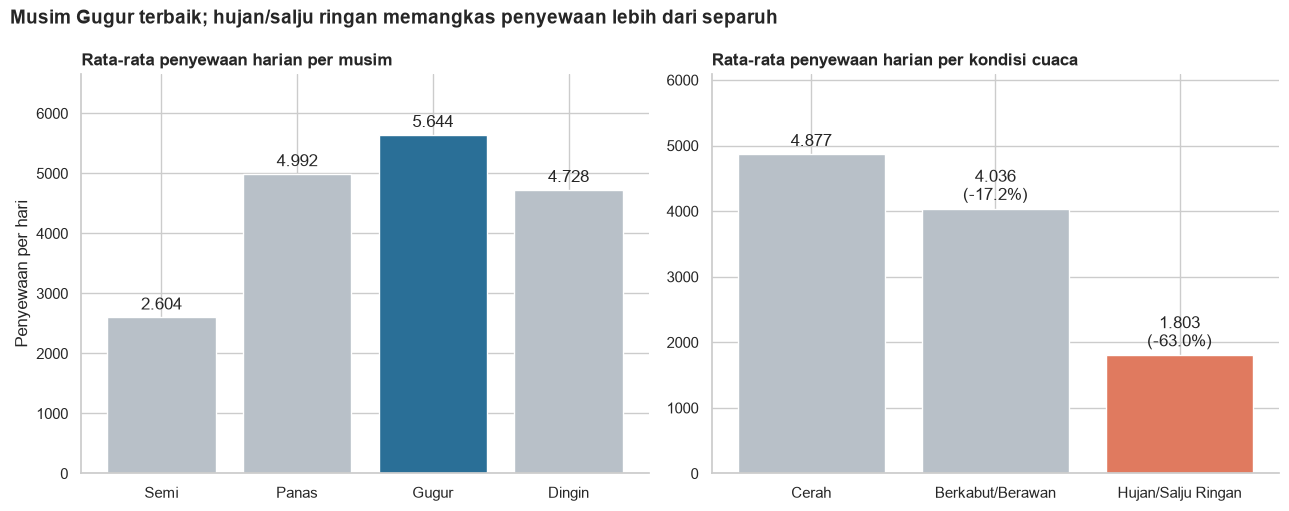

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

# Panel kiri: per musim
s_musim = ringkasan_musim['mean']
warna_musim = [C_PRIMARY if v == s_musim.max() else C_MUTED for v in s_musim.values]
bars = axes[0].bar(s_musim.index.astype(str), s_musim.values, color=warna_musim)
axes[0].bar_label(bars, labels=[f'{v:,.0f}'.replace(',', '.') for v in s_musim.values], padding=3)
axes[0].set_title('Rata-rata penyewaan harian per musim', loc='left', fontweight='bold')
axes[0].set_ylabel('Penyewaan per hari')
axes[0].set_ylim(0, s_musim.max() * 1.18)

# Panel kanan: per cuaca (dengan % selisih vs cerah)
s_cuaca = ringkasan_cuaca['mean']
warna_cuaca = [C_ACCENT if v == s_cuaca.min() else C_MUTED for v in s_cuaca.values]
label_cuaca = [f'{v:,.0f}'.replace(',', '.') if c == 'Cerah' else f"{v:,.0f}".replace(',', '.') + f"\n({(v / s_cuaca['Cerah'] - 1) * 100:+.1f}%)"
               for c, v in s_cuaca.items()]
bars = axes[1].bar(s_cuaca.index.astype(str), s_cuaca.values, color=warna_cuaca)
axes[1].bar_label(bars, labels=label_cuaca, padding=3)
axes[1].set_title('Rata-rata penyewaan harian per kondisi cuaca', loc='left', fontweight='bold')
axes[1].set_ylim(0, s_cuaca.max() * 1.25)
axes[1].set_ylabel('')

for ax in axes:
    ax.set_xlabel('')
sns.despine()
fig.suptitle('Musim Gugur terbaik; hujan/salju ringan memangkas penyewaan lebih dari separuh', x=0.01, ha='left', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**Penjelasan:** Panel kiri menunjukkan musim Gugur sebagai musim tersibuk (batang biru) dan Semi sebagai yang terendah. Panel kanan menunjukkan penurunan bertahap seiring memburuknya cuaca: −17% saat berkabut/berawan dan −63% saat hujan/salju ringan (batang oranye) dibanding hari cerah.

### Pertanyaan 3: Bagaimana pertumbuhan penyewaan 2012 dibanding 2011, dan pengguna mana yang tumbuh lebih cepat?

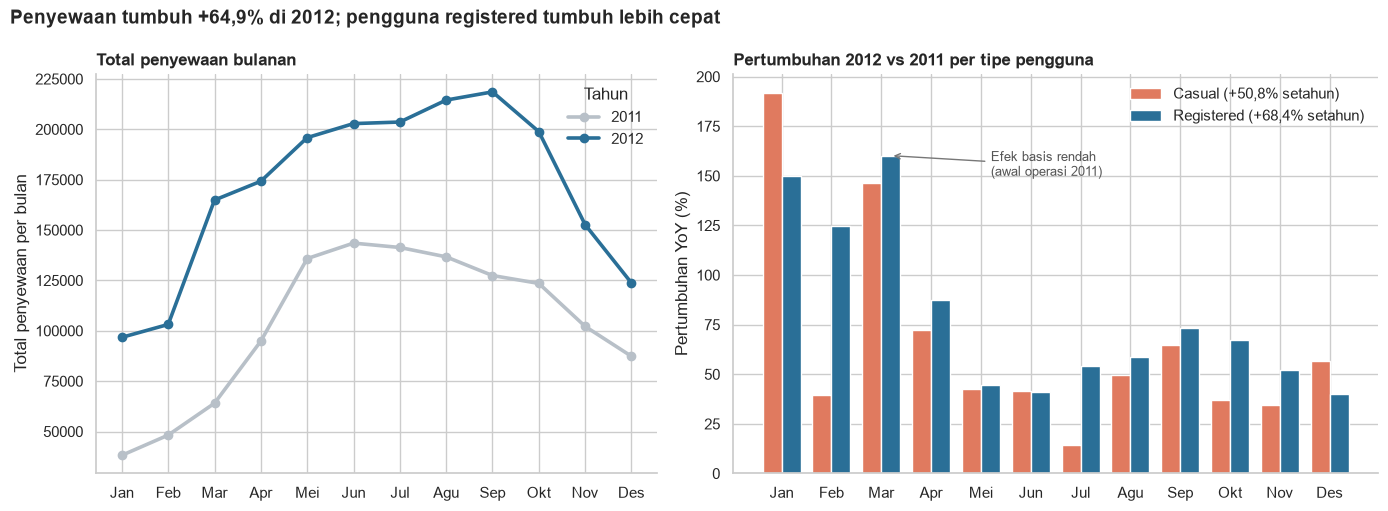

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={'width_ratios': [1, 1.15]})

# Panel kiri: total bulanan per tahun
for tahun, c in [(2011, C_MUTED), (2012, C_PRIMARY)]:
    axes[0].plot(range(1, 13), pivot_bulanan['cnt'][tahun].values, marker='o', lw=2.6, color=c, label=str(tahun))
axes[0].set_xticks(range(1, 13))
axes[0].set_xticklabels(month_names)
axes[0].set_ylabel('Total penyewaan per bulan')
axes[0].set_title('Total penyewaan bulanan', loc='left', fontweight='bold')
axes[0].legend(title='Tahun', frameon=False)

# Panel kanan: pertumbuhan YoY per tipe pengguna
x = np.arange(12)
w = 0.38
axes[1].bar(x - w / 2, yoy['yoy_casual_%'], w, color=C_ACCENT, label='Casual (+50,8% setahun)')
axes[1].bar(x + w / 2, yoy['yoy_registered_%'], w, color=C_PRIMARY, label='Registered (+68,4% setahun)')
axes[1].set_xticks(x)
axes[1].set_xticklabels(month_names)
axes[1].set_ylabel('Pertumbuhan YoY (%)')
axes[1].set_title('Pertumbuhan 2012 vs 2011 per tipe pengguna', loc='left', fontweight='bold')
axes[1].legend(frameon=False)
axes[1].annotate('Efek basis rendah\n(awal operasi 2011)', xy=(2 + w / 2, yoy.loc['Mar', 'yoy_registered_%']), xytext=(4.2, 150),
                 fontsize=9.5, color='#555555', arrowprops=dict(arrowstyle='->', color='#777777'))

sns.despine()
fig.suptitle('Penyewaan tumbuh +64,9% di 2012; pengguna registered tumbuh lebih cepat', x=0.01, ha='left', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**Penjelasan:** Garis 2012 (biru) berada di atas 2011 (abu-abu) sepanjang tahun dengan pola musiman yang sama (puncak Juni–September). Pada panel kanan, batang biru (registered) lebih tinggi dari oranye (casual) pada 9 dari 12 bulan, sehingga basis pelanggan tetap tumbuh lebih cepat. Lonjakan Januari–Maret terutama akibat basis 2011 yang masih sangat kecil.

## Analisis Lanjutan (Opsional)

Teknik yang digunakan adalah **manual grouping & binning** (tanpa machine learning):
1. **Binning suhu** (`pd.cut`) menjadi 4 kelompok: Dingin (<10°C), Sejuk (10–20°C), Hangat (20–30°C), Panas (≥30°C) untuk melihat suhu ideal penyewaan.
2. **Pengelompokan waktu** dalam sehari (Dini Hari, Pagi, Siang, Sore, Malam) per tipe hari sebagai dasar jadwal operasional.
3. **Heatmap hari × jam** untuk melihat intensitas permintaan secara menyeluruh.

In [25]:
# 1) Binning suhu harian
day_df['temp_group'] = pd.cut(day_df['temp_c'], bins=[-np.inf, 10, 20, 30, np.inf],
                              labels=['Dingin (<10°C)', 'Sejuk (10–20°C)', 'Hangat (20–30°C)', 'Panas (≥30°C)'], right=False)
by_temp = day_df.groupby('temp_group', observed=True)['cnt'].agg(['count', 'mean']).round(0)
print(by_temp.to_string())

# 2) Pengelompokan waktu dalam sehari
hour_df['time_segment'] = pd.cut(hour_df['hr'], bins=[-1, 5, 9, 15, 19, 23],
                                 labels=['Dini Hari (00–05)', 'Pagi (06–09)', 'Siang (10–15)', 'Sore (16–19)', 'Malam (20–23)'])
segmen = hour_df.pivot_table(index='time_segment', columns='day_type', values='cnt', aggfunc='mean', observed=True).round(0)
print('\nRata-rata penyewaan per jam menurut segmen waktu:')
print(segmen.to_string())

                  count    mean
temp_group                     
Dingin (<10°C)       60  1678.0
Sejuk (10–20°C)     299  3692.0
Hangat (20–30°C)    300  5662.0
Panas (≥30°C)        72  5410.0

Rata-rata penyewaan per jam menurut segmen waktu:
day_type           Hari Kerja  Akhir Pekan/Libur
time_segment                                    
Dini Hari (00–05)        16.0               43.0
Pagi (06–09)            278.0               85.0
Siang (10–15)           180.0              339.0
Sore (16–19)            415.0              297.0
Malam (20–23)           166.0              130.0


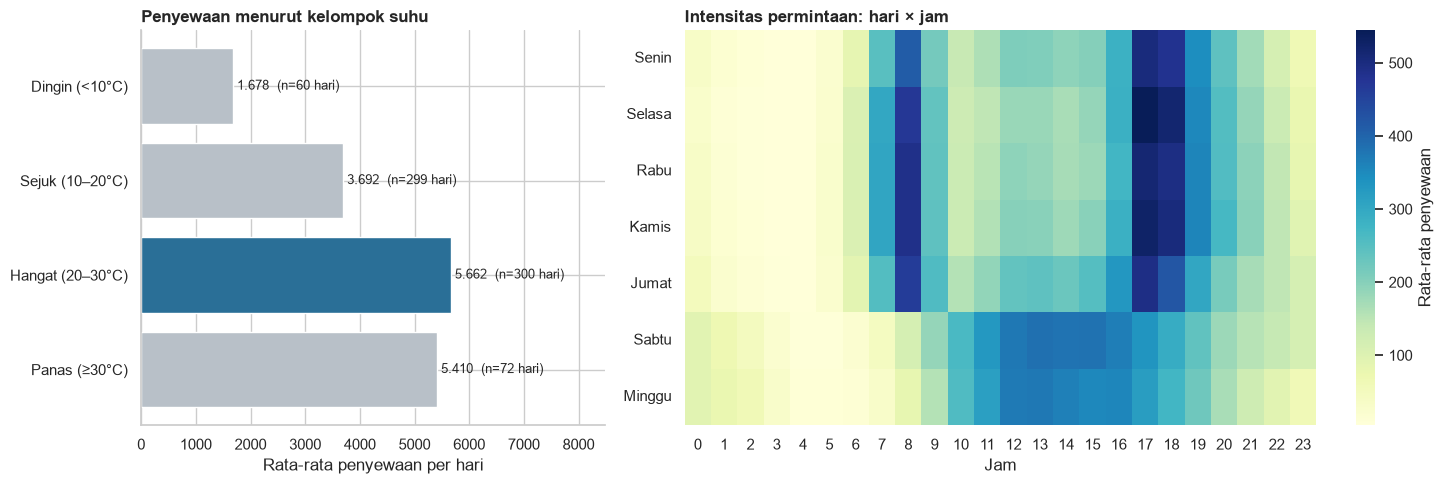

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [1, 1.7]})

# Binning suhu
warna_t = [C_PRIMARY if v == by_temp['mean'].max() else C_MUTED for v in by_temp['mean']]
bars = axes[0].barh(by_temp.index.astype(str), by_temp['mean'], color=warna_t)
axes[0].bar_label(bars, labels=[f"{m:,.0f}".replace(',', '.') + f'  (n={int(n)} hari)' for m, n in zip(by_temp['mean'], by_temp['count'])], padding=3, fontsize=9)
axes[0].invert_yaxis()
axes[0].set_xlim(0, by_temp['mean'].max() * 1.5)
axes[0].set_xlabel('Rata-rata penyewaan per hari')
axes[0].set_title('Penyewaan menurut kelompok suhu', loc='left', fontweight='bold')

# Heatmap hari x jam
heat = hour_df.pivot_table(index='weekday_name', columns='hr', values='cnt', aggfunc='mean', observed=False)
sns.heatmap(heat, cmap='YlGnBu', ax=axes[1], cbar_kws={'label': 'Rata-rata penyewaan'})
axes[1].set_xlabel('Jam')
axes[1].set_ylabel('')
axes[1].tick_params(axis='y', rotation=0)
axes[1].set_title('Intensitas permintaan: hari × jam', loc='left', fontweight='bold')

sns.despine(ax=axes[0])
plt.tight_layout()
plt.show()

**Insight:**
- Penyewaan tertinggi pada kelompok suhu **Hangat (20–30°C)**. Rata-rata ±5.662 sepeda/hari (Hangat) dan ±5.410 (Panas) dibanding hanya ±1.678 pada suhu **Dingin (<10°C)**, sehingga suhu merupakan faktor kunci selain hujan.
- Heatmap memperlihatkan pita intens pukul **07–09 dan 16–19** pada Senin–Jumat, serta blok siang hari (**11–16**) pada Sabtu–Minggu. Ini mengonfirmasi pola Pertanyaan 1.
- Segmen **Dini Hari** hari kerja adalah yang paling sepi, sehingga paling cocok untuk jadwal perawatan dan rebalancing armada.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Pada **hari kerja** permintaan memiliki dua puncak komuter, yaitu pukul **08:00 (±477 sepeda/jam)** dan **17:00 (±525 sepeda/jam)**, sedangkan pada **akhir pekan/libur** hanya ada satu puncak landai sekitar **13:00 (±373 sepeda/jam)**. Puncak sore hari kerja ±41% lebih tinggi dari puncak akhir pekan, dan dini hari hari kerja nyaris tanpa permintaan.
- **Conclusion pertanyaan 2:** Musim **Gugur** paling ramai (±5.644 sepeda/hari) dan **Semi** paling sepi (±2.604, sekitar 54% lebih rendah). Dibanding hari cerah (±4.877/hari), cuaca **berkabut/berawan** menurunkan penyewaan ±**17%** dan **hujan/salju ringan** ±**63%** (±1.803/hari). Suhu berkorelasi positif sedang (r ≈ 0,63) dengan penyewaan.
- **Conclusion pertanyaan 3:** Total penyewaan 2012 tumbuh **+64,9%** dibanding 2011. Pengguna **registered (+68,4%)** tumbuh lebih cepat daripada **casual (+50,8%)**, dan porsi casual turun dari 19,9% ke 18,2%. Pertumbuhan tertinggi pada **Maret (+157%)** dan **Januari (+153%)** (terutama efek basis rendah), dan terendah pada **Juni (+41,3%)**.

**Rekomendasi Action Item:**
- **Rebalancing armada berbasis jam (hari kerja):** siapkan sepeda penuh di area permukiman/stasiun sebelum **07:00** dan di area perkantoran sebelum **16:30**; pada akhir pekan, pastikan stok penuh di area rekreasi/pusat kota pukul **10:00–17:00**.
- **Jadwal perawatan:** gunakan jendela **00:00–05:00 hari kerja** (permintaan terendah) untuk perawatan dan pengisian ulang, serta musim **Semi/Dingin** untuk perawatan besar karena permintaan harian lebih rendah.
- **Antisipasi cuaca:** integrasikan prakiraan cuaca ke perencanaan operasional. Saat prakiraan hujan/salju ringan, kurangi sepeda yang disebar (permintaan bisa turun ±63%) dan alihkan tim ke perawatan; berikan promo/insentif pada hari berkabut yang masih ±17% lebih rendah.
- **Konversi casual → registered:** pengguna casual tumbuh lebih lambat dan paling aktif di akhir pekan siang hari cerah. Tawarkan promo membership pada jam/hari tersebut, terutama di musim Gugur–Panas.
- **Persiapan kapasitas musiman:** tambah kapasitas dan staf sebelum periode puncak (musim Panas–Gugur, Jun–Sep), dan pantau agar pertumbuhan YoY tetap di atas 40% yang terlihat pada bulan-bulan pertengahan 2012.